# Proyek Akhir Praktikum Data Science
## Deteksi Anomali Trafik Jaringan untuk Identifikasi Serangan DDoS

Notebook ini berisi tahap *Business Understanding*, *Data Gathering*, *Exploratory Data Analysis (EDA)*, serta *Cleaning dan Preprocessing*.

## Import Library

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

## Load Dataset

In [2]:
df = pd.read_csv("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")
df.columns = df.columns.str.strip()

df.head()

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443,192.168.10.5,54865,6,7/7/2017 3:30,3,2,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80,192.168.10.5,55054,6,7/7/2017 3:30,109,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80,192.168.10.5,55055,6,7/7/2017 3:30,52,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443,192.168.10.16,46236,6,7/7/2017 3:30,34,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443,192.168.10.5,54863,6,7/7/2017 3:30,3,2,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


# 1. Business Understanding

## 1.1 Latar Belakang

Serangan *Distributed Denial of Service* (DDoS) dapat mengganggu ketersediaan layanan jaringan dengan membanjiri target menggunakan trafik dalam jumlah besar, sehingga pengguna yang sah mengalami kesulitan mengakses layanan. Oleh karena itu, diperlukan pendekatan untuk membedakan trafik normal dan trafik serangan DDoS berdasarkan karakteristik aliran trafik jaringan. Proyek ini berfokus pada pengujian model klasifikasi untuk membedakan trafik berlabel `BENIGN` dan `DDoS` menggunakan dataset yang diperoleh dari Kaggle dan diidentifikasi berkaitan dengan CICIDS2017.

## 1.2 Rumusan Masalah

Permasalahan utama dalam proyek ini adalah menguji sejauh mana model klasifikasi dapat membedakan aliran trafik jaringan berlabel `BENIGN` dan `DDoS` berdasarkan karakteristik trafik yang tersedia dalam dataset yang digunakan.

## 1.3 Tujuan Proyek

Tujuan proyek ini adalah menguji kemampuan model klasifikasi dalam membedakan aliran trafik jaringan berlabel `BENIGN` dan `DDoS` berdasarkan karakteristik trafik dalam dataset yang digunakan.

## 1.4 Ruang Lingkup

1. Menggunakan pendekatan *supervised learning* dengan tugas klasifikasi biner untuk membedakan trafik `BENIGN` dan `DDoS`.
2. Menggunakan dataset berbentuk CSV yang diperoleh dari Kaggle.
3. Melaksanakan tahapan pemahaman data, eksplorasi data, *cleaning*, *preprocessing*, pemodelan, dan evaluasi.
4. Menggunakan algoritma Random Forest sebagai satu-satunya model klasifikasi yang diuji.
5. Mengevaluasi model berdasarkan data pengujian tanpa menerapkan model secara langsung pada jaringan nyata (*real-time deployment*).

## 1.5 Metode yang Digunakan

Proyek ini menggunakan pendekatan *supervised learning* dengan metode klasifikasi biner. Algoritma yang digunakan adalah Random Forest, yaitu algoritma klasifikasi berbasis gabungan sejumlah pohon keputusan.

Model akan mempelajari pola dari karakteristik aliran trafik yang telah memiliki label, kemudian digunakan untuk memprediksi kelas trafik pada data pengujian. Kelas yang diprediksi adalah `BENIGN` dan `DDoS`.

## 1.6 Metrik Evaluasi

Performa model Random Forest akan dievaluasi menggunakan empat metrik:

1. **Accuracy**, untuk mengukur proporsi prediksi yang benar terhadap seluruh data pengujian.
2. **Precision**, untuk mengukur ketepatan prediksi pada setiap kelas.
3. **Recall**, untuk mengukur kemampuan model mengenali data yang termasuk dalam setiap kelas.
4. **F1-score**, untuk mengukur keseimbangan antara precision dan recall.

Selain itu, *confusion matrix* digunakan untuk menunjukkan jumlah prediksi benar dan salah pada masing-masing kelas. Seluruh komponen tersebut dianalisis secara bersama-sama.

## 1.7 Pertanyaan Penelitian

1. Seberapa baik model Random Forest dapat membedakan aliran trafik jaringan berlabel `BENIGN` dan `DDoS` berdasarkan karakteristik trafik dalam dataset yang digunakan?
2. Bagaimana kinerja model Random Forest berdasarkan nilai accuracy, precision, recall, dan F1-score pada data pengujian?
3. Jenis kesalahan klasifikasi apa yang terjadi ketika model Random Forest memprediksi trafik `BENIGN` dan `DDoS` berdasarkan hasil *confusion matrix*?

## 1.8 Kriteria Keberhasilan

Keberhasilan proyek dinilai berdasarkan kemampuan model Random Forest dalam membedakan kedua kelas, hasil evaluasi menggunakan accuracy, precision, recall, dan F1-score, serta analisis kesalahan prediksi melalui *confusion matrix*.

Tidak ditetapkan ambang performa numerik sebelum eksperimen dilakukan. Kesimpulan mengenai kemampuan model dibuat berdasarkan hasil pengujian.

# 2. Data Gathering

## 2.1 Sumber Dataset

Dataset diperoleh dari Kaggle dengan nama *Friday-WorkingHours-Afternoon-DDos*.

- **Nama file:** `Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv`
- **Pengunggah:** `ishasingh03`
- **Format:** CSV
- **Tautan:** [Dataset di Kaggle](https://www.kaggle.com/datasets/ishasingh03/friday-workinghours-afternoon-ddos)

Nama file, struktur kolom, jumlah data, dan distribusi label konsisten dengan bagian DDoS pada CICIDS2017. Dokumentasi resmi CICIDS2017 dapat dilihat pada [Canadian Institute for Cybersecurity](https://www.unb.ca/cic/datasets/ids-2017.html).

Kesesuaian identitas dataset diperiksa melalui nama file, struktur kolom, jumlah data, dan distribusi label.

## 2.2 Deskripsi dan Struktur Dataset

Setiap baris merepresentasikan satu aliran trafik (*network flow*). Kolom-kolomnya berisi identitas aliran, statistik paket, karakteristik waktu, dan label kelas.

| Komponen | Keterangan |
|---|---|
| Jumlah baris | 225.745 |
| Jumlah kolom | 85 (84 fitur dan 1 target) |
| Kolom target | `Label` |
| Jumlah kelas | 2 |

| Label | Jumlah Data | Persentase |
|---|---:|---:|
| `BENIGN` | 97.718 | 43,29% |
| `DDoS` | 128.027 | 56,71% |
| **Total** | **225.745** | **100%** |

Kelas `DDoS` memiliki jumlah data lebih banyak daripada kelas `BENIGN`. Distribusi ini akan diperhatikan pada saat eksplorasi dan evaluasi.

Pemeriksaan awal juga menemukan empat nilai kosong, 64 nilai tak hingga, dua baris duplikat, dan sepuluh kolom konstan. Kondisi tersebut akan diperiksa lebih lanjut pada tahap EDA dan Cleaning.

## 2.3 Deskripsi Fitur

Pada CICFlowMeter, arah *forward* (Fwd) mengikuti arah dari sumber ke tujuan berdasarkan paket pertama yang diamati, sedangkan *backward* (Bwd) adalah arah sebaliknya. *Inter-arrival time* (IAT) merupakan selang waktu antara paket yang berurutan.

| Kelompok | Kolom | Keterangan |
|---|---|---|
| Identitas dan metadata | `Flow ID`, `Source IP`, `Source Port`, `Destination IP`, `Destination Port`, `Protocol`, `Timestamp` | Identitas koneksi, alamat dan port komunikasi, protokol, serta waktu aliran. |
| Durasi dan paket | `Flow Duration`, `Total Fwd Packets`, `Total Backward Packets`, `Total Length of Fwd Packets`, `Total Length of Bwd Packets` | Durasi aliran, jumlah paket, dan total ukuran paket pada setiap arah. |
| Panjang paket | `Fwd/Bwd Packet Length` (Max, Min, Mean, Std), `Min/Max/Mean/Std/Variance Packet Length`, `Average Packet Size`, `Avg Fwd/Bwd Segment Size` | Statistik ukuran paket dan segmen pada setiap arah maupun keseluruhan aliran. |
| Laju trafik dan IAT | `Flow Bytes/s`, `Flow Packets/s`, `Fwd/Bwd Packets/s`, `Flow IAT`, `Fwd IAT`, `Bwd IAT` (Mean, Std, Max, Min; Total untuk Fwd dan Bwd) | Laju byte dan paket per detik serta statistik selang waktu antar-paket. |
| Header dan TCP flags | `Fwd/Bwd PSH Flags`, `Fwd/Bwd URG Flags`, `Fwd/Bwd Header Length`, `FIN/SYN/RST/PSH/ACK/URG/CWE/ECE Flag Count` | Jumlah flag TCP dan panjang header pada aliran. |
| Bulk dan subflow | `Down/Up Ratio`, `Fwd/Bwd Avg Bytes/Bulk`, `Fwd/Bwd Avg Packets/Bulk`, `Fwd/Bwd Avg Bulk Rate`, `Subflow Fwd/Bwd Packets`, `Subflow Fwd/Bwd Bytes` | Rasio arah trafik, statistik kelompok paket (*bulk*), dan subflow. |
| TCP window dan aktivitas | `Init_Win_bytes_forward/backward`, `act_data_pkt_fwd`, `min_seg_size_forward`, `Active` dan `Idle` (Mean, Std, Max, Min) | Informasi TCP window, segmen, serta durasi periode aktif dan tidak aktif. |
| Target | `Label` | Kelas `BENIGN` atau `DDoS`; digunakan sebagai target prediksi. |

Definisi fitur mengacu pada [dokumentasi CICFlowMeter](https://github.com/ahlashkari/CICFlowMeter/blob/master/ReadMe.txt). Kolom `Fwd Header Length.1` merupakan kolom duplikat dari `Fwd Header Length` pada file yang digunakan.

## 2.4 Alasan Pemilihan, Kredibilitas, dan Batasan Dataset

**Alasan pemilihan**

1. Dataset memiliki label `BENIGN` dan `DDoS` yang sesuai dengan klasifikasi biner menggunakan *supervised learning*.
2. Jumlah data dan fitur cukup besar untuk melakukan eksplorasi serta pemodelan.
3. Fitur mencakup durasi aliran, jumlah dan ukuran paket, laju trafik, interval waktu, serta karakteristik jaringan lainnya.
4. Dataset memiliki beberapa kondisi kualitas data yang dapat dipelajari pada tahap Cleaning dan Preprocessing.

**Kredibilitas**

Sumber pengunduhan dicantumkan dari Kaggle. Struktur, nama file, jumlah record, dan labelnya konsisten dengan dataset CICIDS2017. Definisi fitur dapat diperiksa melalui dokumentasi CICFlowMeter.

**Lisensi**

Dataset mencantumkan lisensi **Apache License 2.0**. Teks lisensi dapat dilihat pada [Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0).

**Batasan**

Dataset berasal dari skenario pengambilan trafik tertentu. Oleh karena itu, hasil eksperimen tidak otomatis mewakili seluruh jaringan atau kondisi serangan nyata. Kesimpulan proyek dibatasi pada data yang digunakan.

# 3. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami distribusi kelas, karakteristik fitur, dan kualitas data sebelum proses Cleaning dan Preprocessing. Fitur divisualisasikan berdasarkan kelompok karakteristik. Tidak semua kolom ditampilkan satu per satu agar grafik tidak berulang, tetapi kelompok utama paket, laju, waktu, Active/Idle, dan TCP flags tetap terwakili.

## 3.1 Gambaran Umum Dataset

Pemeriksaan awal dilakukan untuk melihat ukuran data, contoh baris, tipe kolom, dan statistik deskriptif.

In [3]:
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (225745, 85)


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443,192.168.10.5,54865,6,7/7/2017 3:30,3,2,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80,192.168.10.5,55054,6,7/7/2017 3:30,109,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80,192.168.10.5,55055,6,7/7/2017 3:30,52,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443,192.168.10.16,46236,6,7/7/2017 3:30,34,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443,192.168.10.5,54863,6,7/7/2017 3:30,3,2,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 85 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Flow ID                      225745 non-null  object 
 1   Source IP                    225745 non-null  object 
 2   Source Port                  225745 non-null  int64  
 3   Destination IP               225745 non-null  object 
 4   Destination Port             225745 non-null  int64  
 5   Protocol                     225745 non-null  int64  
 6   Timestamp                    225745 non-null  object 
 7   Flow Duration                225745 non-null  int64  
 8   Total Fwd Packets            225745 non-null  int64  
 9   Total Backward Packets       225745 non-null  int64  
 10  Total Length of Fwd Packets  225745 non-null  int64  
 11  Total Length of Bwd Packets  225745 non-null  int64  
 12  Fwd Packet Length Max        225745 non-null  int64  
 13 

In [5]:
angka = df.select_dtypes(include=np.number).replace([np.inf, -np.inf], np.nan)
display(angka.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Source Port,225745.0,38257.57,23057.30,0.0,18990.0,49799.0,58296.0,65534.0
Destination Port,225745.0,8879.62,19754.65,0.0,80.0,80.0,80.0,65532.0
Protocol,225745.0,7.60,3.88,0.0,6.0,6.0,6.0,17.0
Flow Duration,225745.0,16241648.53,31524374.23,-1.0,71180.0,1452333.0,8805237.0,119999937.0
Total Fwd Packets,225745.0,4.87,15.42,1.0,2.0,3.0,5.0,1932.0
...,...,...,...,...,...,...,...,...
Active Min,225745.0,177620.09,784260.22,0.0,0.0,0.0,1862.0,100000000.0
Idle Mean,225745.0,10322143.42,21853028.15,0.0,0.0,0.0,8239725.0,120000000.0
Idle Std,225745.0,3611942.93,12756893.46,0.0,0.0,0.0,0.0,65300000.0
Idle Max,225745.0,12878128.94,26921263.65,0.0,0.0,0.0,8253838.0,120000000.0


In [6]:
display(df.describe(include="object").T)

,count,unique,top,freq
Flow ID,225745,86421,192.168.10.25-17.253.14.125-123-123-17,44
Source IP,225745,2067,172.16.0.1,128181
Destination IP,225745,2554,192.168.10.50,128834
Timestamp,225745,93,7/7/2017 4:13,11188
Label,225745,2,DDoS,128027


**Temuan:** Dataset berisi 225.745 baris dan 85 kolom. Sebagian besar kolom merupakan fitur numerik yang menggambarkan karakteristik aliran trafik. Kolom bertipe teks terutama berisi identitas aliran, alamat IP, waktu, dan label.

## 3.2 Distribusi Label

Distribusi label diperiksa untuk mengetahui jumlah trafik normal dan trafik DDoS.

,Jumlah,Persentase (%)
Label,,
DDoS,128027,56.71
BENIGN,97718,43.29


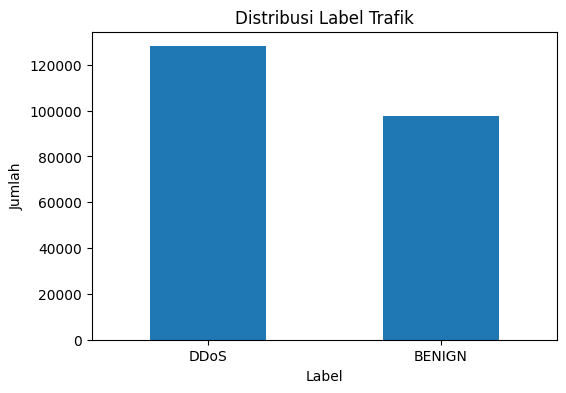

In [7]:
label_count = df["Label"].value_counts()
label_table = pd.DataFrame({
    "Jumlah": label_count,
    "Persentase (%)": (label_count / len(df) * 100).round(2)
})
display(label_table)

label_count.plot(kind="bar", figsize=(6, 4))
plt.title("Distribusi Label Trafik")
plt.xlabel("Label")
plt.ylabel("Jumlah")
plt.xticks(rotation=0)
plt.show()

**Temuan:** Terdapat 97.718 aliran `BENIGN` (43,29%) dan 128.027 aliran `DDoS` (56,71%). Kelas DDoS lebih banyak, tetapi kedua kelas tetap memiliki jumlah data yang cukup besar. Distribusi ini perlu dipertahankan saat pembagian data latih dan data uji.

## 3.3 Pemeriksaan Kualitas Data

Pemeriksaan meliputi nilai kosong, nilai tak hingga, baris duplikat, kolom konstan, dan nilai negatif. Nilai negatif tidak langsung dianggap salah karena beberapa fitur dapat memakai nilai penanda tertentu.

In [8]:
angka = df.select_dtypes(include=np.number)
kualitas = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Infinity": np.isinf(angka).sum(),
    "Negatif": (angka < 0).sum(),
    "Nilai unik": df.nunique(dropna=False)
})
display(kualitas.loc[(kualitas[["Missing", "Infinity", "Negatif"]] > 0).any(axis=1)])

print("Baris duplikat:", df.duplicated().sum())
print("Kolom konstan:", df.columns[df.nunique(dropna=False) <= 1].tolist())

,Missing,Infinity,Negatif,Nilai unik
Flow Bytes/s,4,30.0,2.0,202294
Flow Duration,0,0.0,2.0,187752
Flow IAT Max,0,0.0,2.0,139745
Flow IAT Mean,0,0.0,2.0,193666
Flow IAT Min,0,0.0,108.0,11093
Flow Packets/s,0,34.0,2.0,194094
Fwd IAT Min,0,0.0,6.0,8820
Init_Win_bytes_backward,0,0.0,88299.0,1922
Init_Win_bytes_forward,0,0.0,32925.0,1804


Baris duplikat: 2
Kolom konstan: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


**Temuan:** Ditemukan empat nilai kosong, 64 nilai tak hingga, dua baris duplikat, dan sepuluh kolom konstan. Nilai negatif muncul pada beberapa fitur waktu/laju serta `Init_Win_bytes_forward` dan `Init_Win_bytes_backward`. Nilai negatif pada TCP window berupa `-1` dan perlu diperlakukan sebagai penanda nilai tidak tersedia, bukan disamakan dengan nilai negatif pada durasi atau laju trafik. Penanganannya dilakukan pada tahap Preprocessing.

## 3.4 Pemeriksaan Port dan Protocol

Port dan protokol diperiksa karena keduanya dapat menunjukkan pola yang sangat spesifik pada skenario pengambilan data. Pemeriksaan ini membantu menilai risiko model mengandalkan konteks koneksi, bukan karakteristik trafik yang lebih umum.

In [9]:
port_table = pd.crosstab(
    df["Label"], df["Destination Port"].eq(80), normalize="index"
) * 100
port_table.columns = ["Selain port 80", "Port 80"]
display(port_table.round(2))

protocol_table = pd.crosstab(
    df["Label"], df["Protocol"], normalize="index"
) * 100
display(protocol_table.round(2))

,Selain port 80,Port 80
Label,,
BENIGN,90.86,9.14
DDoS,0.00,100.00


Protocol,0,6,17
Label,,,
BENIGN,0.06,66.31,33.64
DDoS,0.00,100.00,0.00


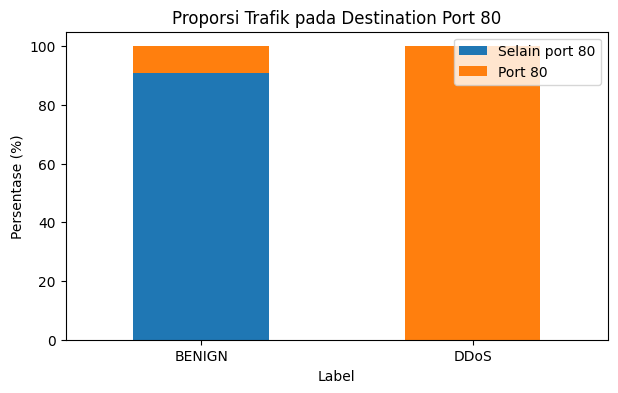

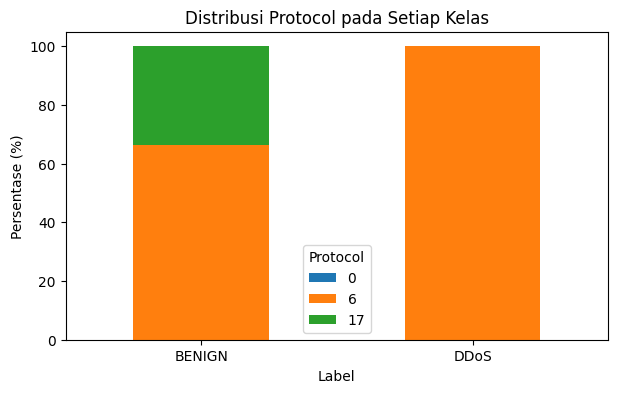

In [10]:
port_table.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.title("Proporsi Trafik pada Destination Port 80")
plt.xlabel("Label")
plt.ylabel("Persentase (%)")
plt.xticks(rotation=0)
plt.show()

protocol_table.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.title("Distribusi Protocol pada Setiap Kelas")
plt.xlabel("Label")
plt.ylabel("Persentase (%)")
plt.xticks(rotation=0)
plt.show()

**Temuan:** Sebanyak 99,9977% data DDoS menggunakan `Destination Port` 80, sedangkan seluruh data DDoS menggunakan `Protocol` 6 (TCP). Pada kelas BENIGN, penggunaan port 80 sekitar 9,14%; sisanya menggunakan port lain. Pola ini sangat kuat pada dataset yang digunakan dan dapat membuat model memanfaatkan jalan pintas. Oleh karena itu, `Source Port`, `Destination Port`, dan `Protocol` tidak digunakan sebagai fitur model. Ketiganya tetap dianalisis sebagai karakteristik dataset.

## 3.5 Jumlah dan Ukuran Paket

Kelompok ini mewakili volume komunikasi pada arah *forward* dan *backward*, serta ukuran paket. Fitur dipilih karena menunjukkan berapa banyak paket dan data yang dikirim pada setiap aliran.

In [11]:
fitur_paket = [
    "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Packet Length Mean", "Fwd Packet Length Mean", "Bwd Packet Length Mean"
]

data_paket = df[["Label"] + fitur_paket].replace([np.inf, -np.inf], np.nan).dropna()
display(data_paket.groupby("Label")[fitur_paket].median().T.round(2))

Label,BENIGN,DDoS
Total Fwd Packets,2.0,4.0
Total Backward Packets,2.0,4.0
Total Length of Fwd Packets,70.0,26.0
Total Length of Bwd Packets,62.0,11601.0
Packet Length Mean,61.0,833.5
Fwd Packet Length Mean,38.0,7.0
Bwd Packet Length Mean,13.0,1934.5


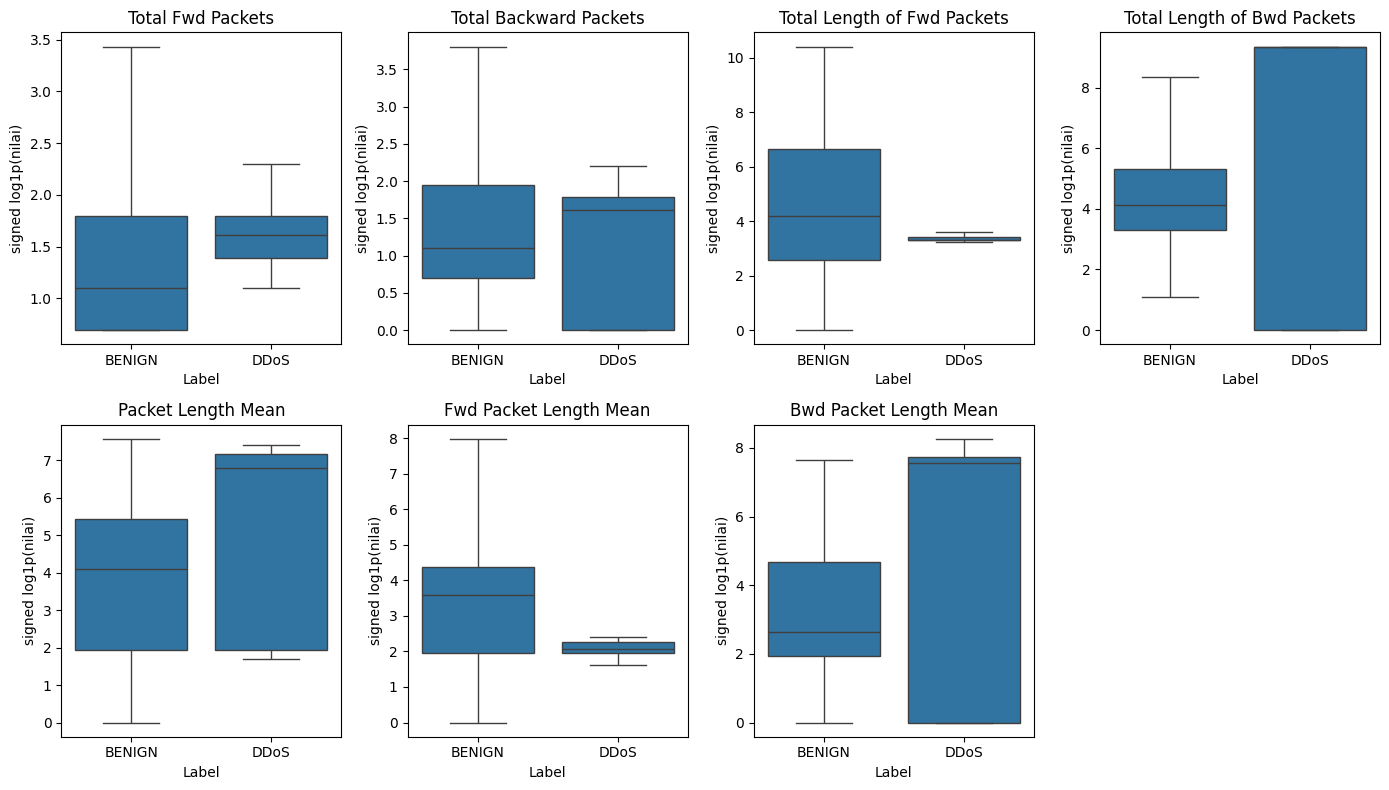

In [12]:
sampel_paket = data_paket.groupby("Label", group_keys=False).sample(
    n=3000, random_state=42
)
sampel_plot = sampel_paket.copy()
sampel_plot[fitur_paket] = np.sign(sampel_plot[fitur_paket]) * np.log1p(
    np.abs(sampel_plot[fitur_paket])
)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for fitur, ax in zip(fitur_paket, axes.flatten()):
    sns.boxplot(data=sampel_plot, x="Label", y=fitur, ax=ax, showfliers=False)
    ax.set_title(fitur)
    ax.set_ylabel("signed log1p(nilai)")
axes.flatten()[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Temuan:** Median dan sebaran jumlah serta ukuran paket berbeda antar kelas. Perbedaan pada fitur arah forward dan backward menunjukkan bahwa kedua arah komunikasi dapat memberikan informasi yang saling melengkapi. Transformasi `signed log1p` hanya digunakan untuk tampilan grafik agar rentang nilai yang lebar lebih mudah dibaca; nilai asli tetap digunakan pada data.

## 3.6 Laju Trafik dan Interval Kedatangan Paket

Kelompok ini mencakup durasi aliran, laju paket/byte, serta *inter-arrival time* (IAT). Fitur-fitur tersebut dipilih untuk melihat kecepatan komunikasi dan pola jeda antar-paket.

In [13]:
fitur_waktu = [
    "Flow Duration", "Flow Bytes/s", "Flow Packets/s",
    "Fwd Packets/s", "Bwd Packets/s", "Flow IAT Mean",
    "Fwd IAT Mean", "Bwd IAT Mean"
]

data_waktu = df[["Label"] + fitur_waktu].replace([np.inf, -np.inf], np.nan).dropna()
display(data_waktu.groupby("Label")[fitur_waktu].median().T.round(2))

Label,BENIGN,DDoS
Flow Duration,172209.00,1878984.00
Flow Bytes/s,2220.04,160.10
Flow Packets/s,27.46,2.59
Fwd Packets/s,14.46,1.67
Bwd Packets/s,3.20,0.07
Flow IAT Mean,59683.70,489282.00
Fwd IAT Mean,4.00,490485.25
Bwd IAT Mean,49.00,19067.00


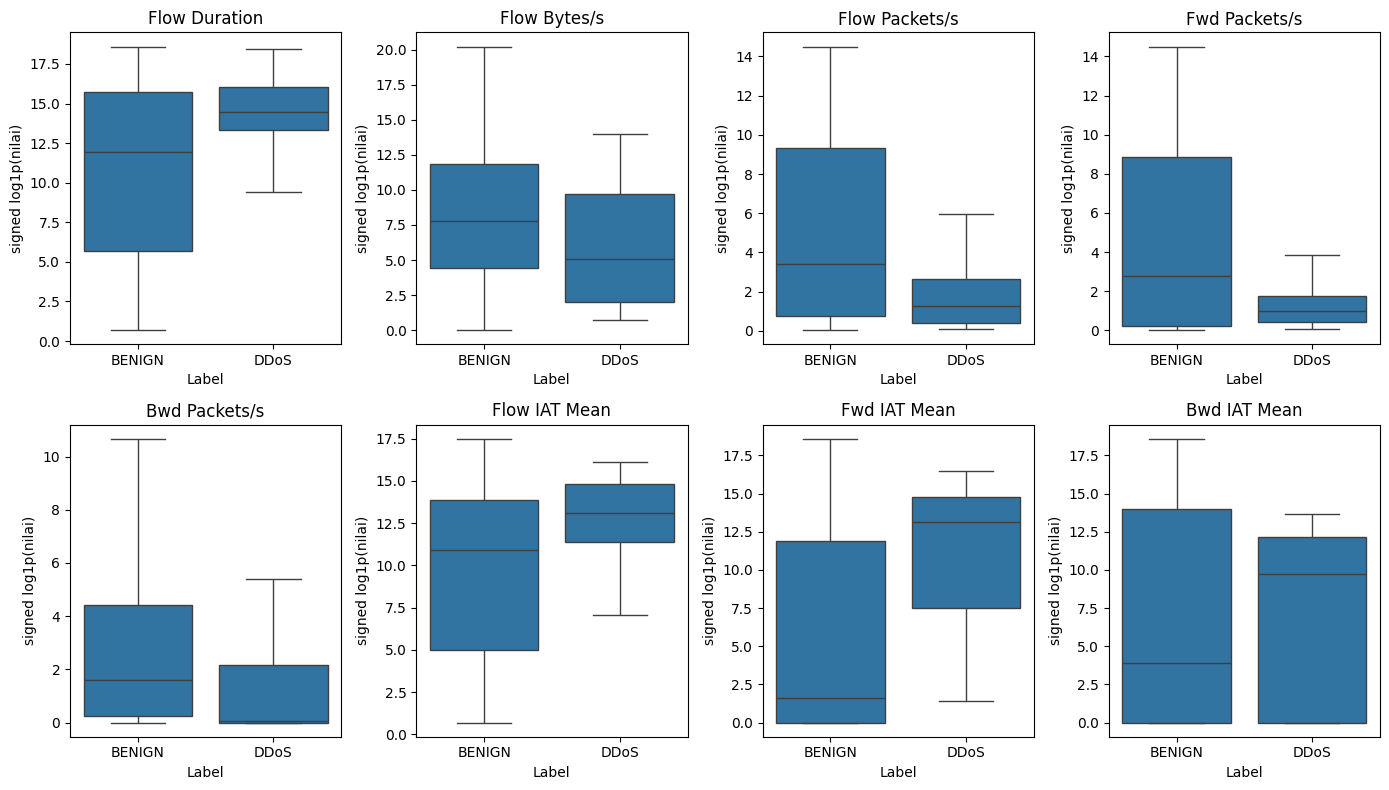

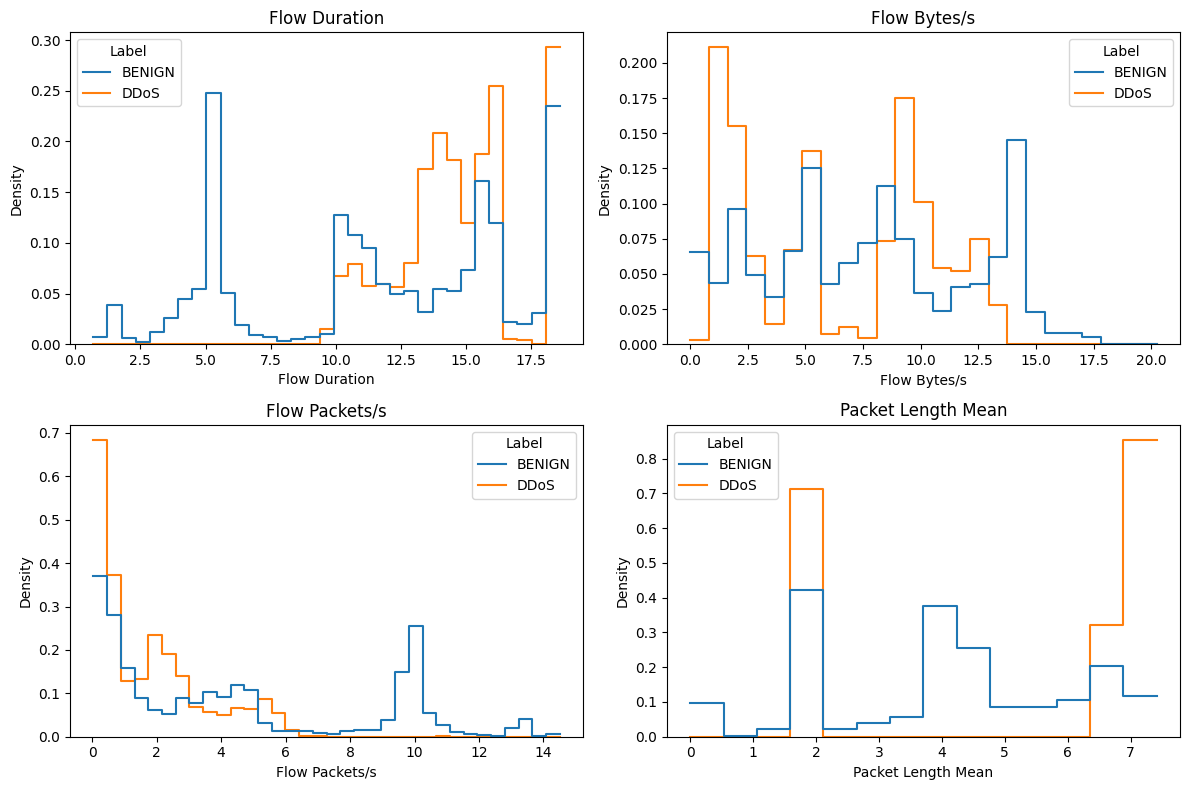

In [14]:
sampel_waktu = data_waktu.groupby("Label", group_keys=False).sample(
    n=3000, random_state=42
)
sampel_plot = sampel_waktu.copy()
sampel_plot[fitur_waktu] = np.sign(sampel_plot[fitur_waktu]) * np.log1p(
    np.abs(sampel_plot[fitur_waktu])
)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for fitur, ax in zip(fitur_waktu, axes.flatten()):
    sns.boxplot(data=sampel_plot, x="Label", y=fitur, ax=ax, showfliers=False)
    ax.set_title(fitur)
    ax.set_ylabel("signed log1p(nilai)")
plt.tight_layout()
plt.show()

fitur_hist = ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Packet Length Mean"]
data_hist = df[["Label"] + fitur_hist].replace([np.inf, -np.inf], np.nan).dropna()
sampel_hist = data_hist.groupby("Label", group_keys=False).sample(
    n=3000, random_state=42
)
sampel_hist[fitur_hist] = np.sign(sampel_hist[fitur_hist]) * np.log1p(
    np.abs(sampel_hist[fitur_hist])
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for fitur, ax in zip(fitur_hist, axes.flatten()):
    sns.histplot(data=sampel_hist, x=fitur, hue="Label", stat="density",
                 common_norm=False, element="step", fill=False, ax=ax)
    ax.set_title(fitur)
plt.tight_layout()
plt.show()

**Temuan:** Fitur durasi, laju trafik, dan IAT memiliki rentang nilai yang lebar. Nilai median antarkelas dapat dibandingkan pada tabel, sedangkan boxplot memperlihatkan sebaran data tanpa menampilkan seluruh pencilan. Fitur-fitur ini dipertahankan sebagai kandidat karena mewakili karakteristik waktu dan laju komunikasi.

## 3.7 Periode Active dan Idle

Fitur `Active` menggambarkan periode ketika aliran trafik aktif, sedangkan `Idle` menggambarkan periode ketika aliran tidak aktif. Fitur-fitur ini dianalisis karena beberapa kolom memiliki banyak nilai nol. Nilai nol tidak otomatis berarti fitur konstan atau missing value.

In [15]:
fitur_aktif = [
    "Active Mean", "Active Std", "Active Max", "Active Min",
    "Idle Mean", "Idle Std", "Idle Max", "Idle Min"
]

zero_table = pd.DataFrame(index=fitur_aktif)
zero_table["Nilai unik"] = df[fitur_aktif].nunique()
for label in ["BENIGN", "DDoS"]:
    zero_table[label + " nol (%)"] = (
        df.loc[df["Label"] == label, fitur_aktif].eq(0).mean() * 100
    )
display(zero_table.round(2))

,Nilai unik,BENIGN nol (%),DDoS nol (%)
Active Mean,40409,70.13,60.15
Active Std,5669,94.18,100.00
Active Max,40313,70.13,60.15
Active Min,38393,70.13,60.15
Idle Mean,35285,70.10,60.13
Idle Std,5857,89.22,90.62
Idle Max,33002,70.10,60.13
Idle Min,48018,70.10,60.13


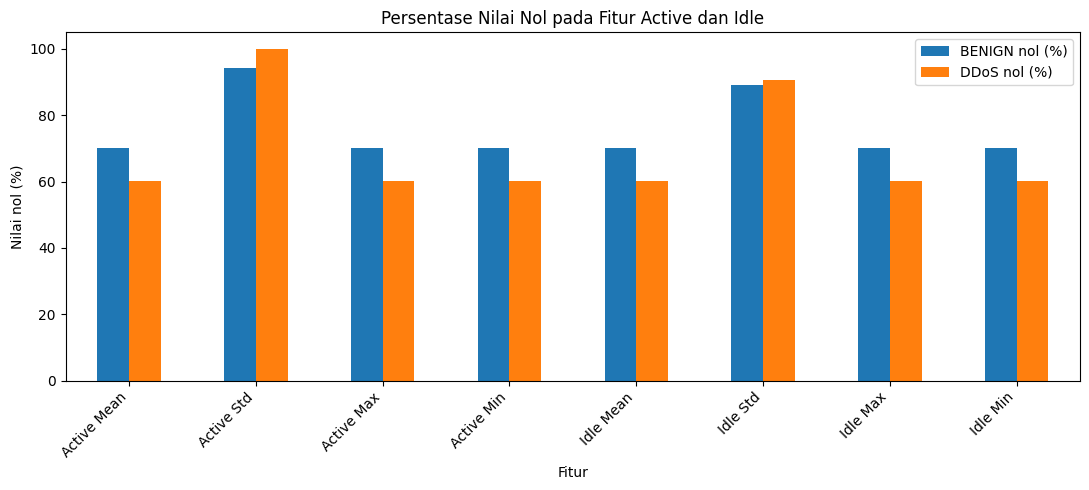

In [16]:
zero_table[["BENIGN nol (%)", "DDoS nol (%)"]].plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Persentase Nilai Nol pada Fitur Active dan Idle")
plt.xlabel("Fitur")
plt.ylabel("Nilai nol (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

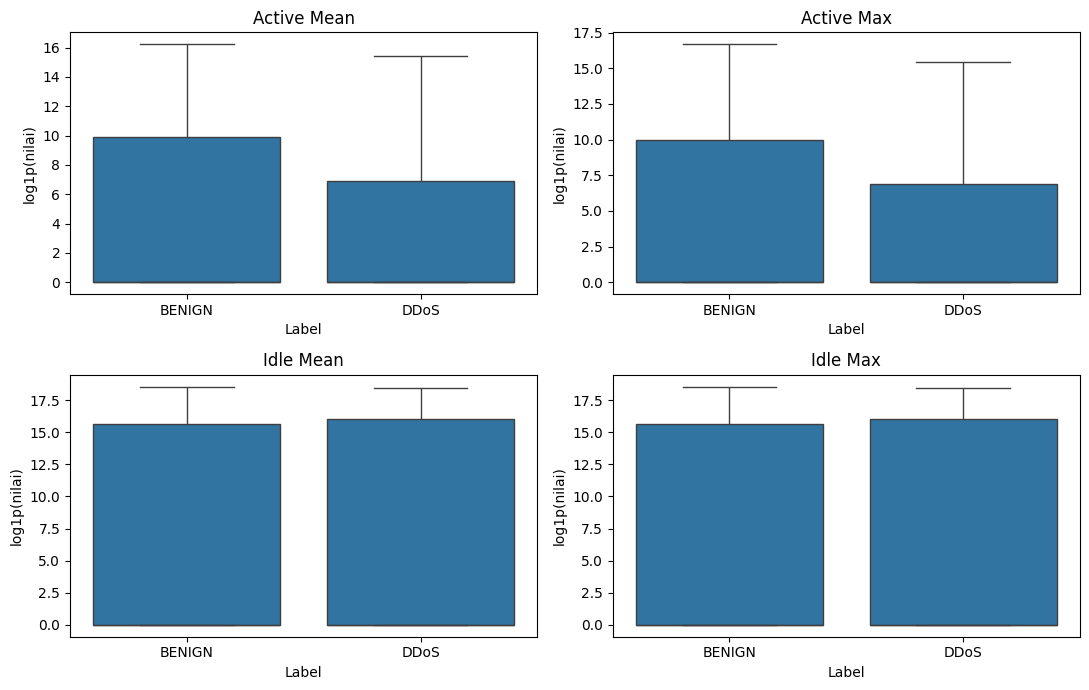

In [17]:
fitur_active_plot = ["Active Mean", "Active Max", "Idle Mean", "Idle Max"]
data_active = df[["Label"] + fitur_active_plot].dropna()
sampel_active = data_active.groupby("Label", group_keys=False).sample(
    n=3000, random_state=42
)
sampel_active[fitur_active_plot] = np.log1p(sampel_active[fitur_active_plot])

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for fitur, ax in zip(fitur_active_plot, axes.flatten()):
    sns.boxplot(data=sampel_active, x="Label", y=fitur, ax=ax, showfliers=False)
    ax.set_title(fitur)
    ax.set_ylabel("log1p(nilai)")
plt.tight_layout()
plt.show()

**Temuan:** Fitur Active dan Idle memang memiliki persentase nilai nol yang tinggi. Namun, setiap fitur masih memiliki banyak nilai unik sehingga tidak termasuk fitur konstan. Secara khusus, `Active Std` bernilai nol pada seluruh data DDoS, tetapi memiliki variasi pada kelas BENIGN. Karena itu, fitur Active/Idle tidak dibuang hanya berdasarkan banyaknya nilai nol. Pola ini tetap perlu diperhatikan saat interpretasi hasil model karena dapat mencerminkan karakteristik skenario dataset.

## 3.8 TCP Flags

TCP flags digunakan dalam proses komunikasi TCP. Persentase aliran yang memiliki nilai flag lebih dari nol dibandingkan antar kelas untuk melihat pola flag yang muncul pada trafik.

In [18]:
fitur_flag = [
    "FIN Flag Count", "SYN Flag Count", "RST Flag Count",
    "PSH Flag Count", "ACK Flag Count", "URG Flag Count", "ECE Flag Count"
]
flag_table = df.groupby("Label")[fitur_flag].apply(lambda x: (x > 0).mean() * 100).T
display(flag_table.round(2))

Label,BENIGN,DDoS
FIN Flag Count,0.59,0.02
SYN Flag Count,7.68,0.00
RST Flag Count,0.03,0.00
PSH Flag Count,21.58,45.45
ACK Flag Count,44.90,54.68
URG Flag Count,32.51,0.00
ECE Flag Count,0.03,0.00


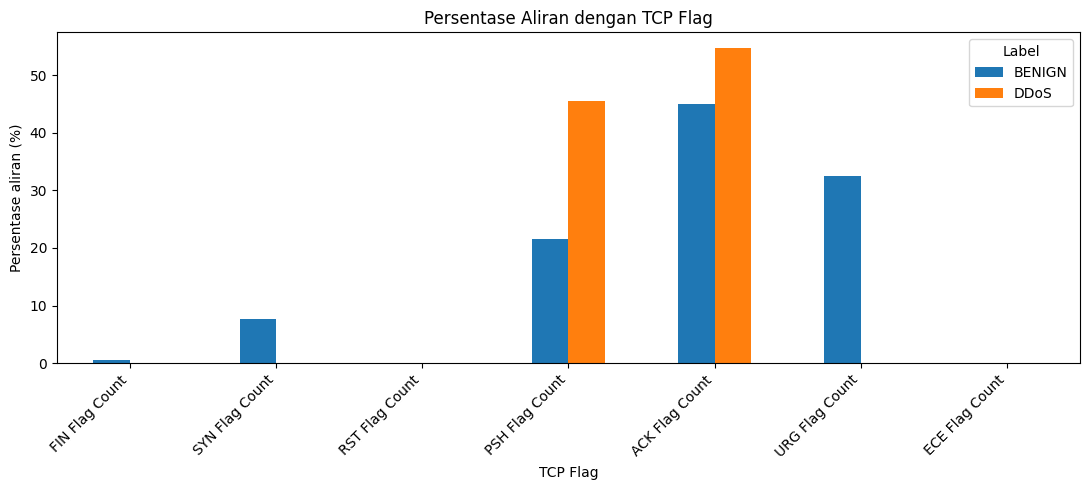

In [19]:
flag_table.plot(kind="bar", figsize=(11, 5))
plt.title("Persentase Aliran dengan TCP Flag")
plt.xlabel("TCP Flag")
plt.ylabel("Persentase aliran (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Temuan:** Persentase kemunculan flag berbeda antar kelas. Contohnya, `PSH Flag Count` dan `ACK Flag Count` lebih sering muncul pada DDoS, sedangkan beberapa flag lain lebih banyak ditemukan pada BENIGN. Perbandingan ini bersifat deskriptif dan tidak digunakan sebagai satu-satunya dasar untuk memilih fitur.

## 3.9 Korelasi Fitur Numerik

Korelasi Pearson digunakan untuk melihat hubungan linear pada beberapa fitur perwakilan dari kelompok paket, laju, waktu, dan Active/Idle. Korelasi bukan bukti sebab-akibat dan tidak digunakan sebagai satu-satunya dasar pemilihan fitur.

In [20]:
fitur_korelasi = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Flow Bytes/s", "Flow Packets/s", "Packet Length Mean",
    "Flow IAT Mean", "Fwd IAT Mean", "Active Mean", "Idle Mean"
]

data_korelasi = df[fitur_korelasi].replace([np.inf, -np.inf], np.nan).dropna().copy()
data_korelasi["Label"] = df.loc[data_korelasi.index, "Label"].map(
    {"BENIGN": 0, "DDoS": 1}
)
korelasi = data_korelasi.corr()
display(korelasi.round(2))

,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Flow IAT Mean,Fwd IAT Mean,Active Mean,Idle Mean,Label
Flow Duration,1.00,0.21,0.15,0.30,0.09,-0.02,-0.06,0.10,0.80,0.77,0.43,0.87,0.03
Total Fwd Packets,0.21,1.00,0.96,0.17,0.94,-0.00,-0.02,0.04,0.06,0.06,0.14,0.11,-0.03
Total Backward Packets,0.15,0.96,1.00,0.16,0.97,-0.01,-0.02,0.10,0.01,0.02,0.10,0.07,-0.07
Total Length of Fwd Packets,0.30,0.17,0.16,1.00,0.07,0.00,-0.03,0.17,0.16,0.29,0.19,0.26,-0.32
Total Length of Bwd Packets,0.09,0.94,0.97,0.07,1.00,-0.00,-0.02,0.15,-0.01,-0.00,0.07,0.04,0.04
Flow Bytes/s,-0.02,-0.00,-0.01,0.00,-0.00,1.00,0.30,0.00,-0.02,-0.01,-0.01,-0.02,-0.04
Flow Packets/s,-0.06,-0.02,-0.02,-0.03,-0.02,0.30,1.00,-0.10,-0.07,-0.05,-0.03,-0.06,-0.14
Packet Length Mean,0.10,0.04,0.10,0.17,0.15,0.00,-0.10,1.00,-0.02,0.04,0.09,0.10,0.45
Flow IAT Mean,0.80,0.06,0.01,0.16,-0.01,-0.02,-0.07,-0.02,1.00,0.92,0.34,0.81,0.13
Fwd IAT Mean,0.77,0.06,0.02,0.29,-0.00,-0.01,-0.05,0.04,0.92,1.00,0.33,0.78,0.02


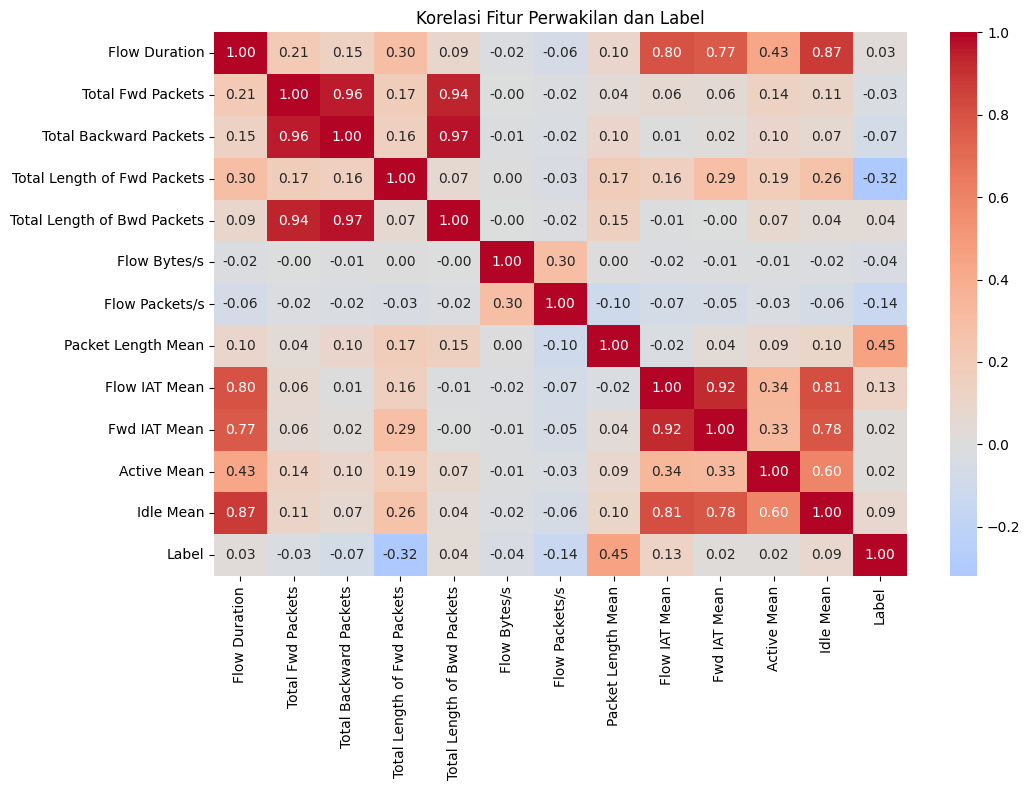

In [21]:
plt.figure(figsize=(11, 8))
sns.heatmap(korelasi, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Korelasi Fitur Perwakilan dan Label")
plt.tight_layout()
plt.show()

**Temuan:** Heatmap memperlihatkan hubungan linear antarf fitur perwakilan dan label. Beberapa fitur dapat memiliki korelasi satu sama lain karena mengukur aspek trafik yang berdekatan. Random Forest dapat menangani hubungan nonlinier, sehingga korelasi ini dipakai sebagai bahan pemahaman data, bukan aturan otomatis untuk membuang fitur.

# 4. Cleaning

Tahap Cleaning menangani nilai kosong, nilai tak hingga, dan baris duplikat yang ditemukan saat EDA. Data awal tetap disimpan pada `df`, sedangkan hasil pembersihan disimpan pada `df_clean`.

## 4.1 Kondisi Sebelum Cleaning

In [22]:
print("Ukuran sebelum cleaning:", df.shape)
print("Nilai kosong:", df.isnull().sum().sum())
print("Nilai tak hingga:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())
print("Baris duplikat:", df.duplicated().sum())

Ukuran sebelum cleaning: (225745, 85)
Nilai kosong: 4
Nilai tak hingga: 64
Baris duplikat: 2


## 4.2 Penanganan Nilai Kosong dan Tak Hingga

Nilai tak hingga diubah menjadi `NaN`. Baris yang memiliki nilai kosong atau tak hingga dihapus karena jumlahnya sangat kecil dibandingkan keseluruhan data.

In [23]:
df_clean = df.replace([np.inf, -np.inf], np.nan).dropna().copy()
print("Baris yang dihapus:", len(df) - len(df_clean))
print("Ukuran setelah menangani missing value:", df_clean.shape)

Baris yang dihapus: 34
Ukuran setelah menangani missing value: (225711, 85)


## 4.3 Penanganan Baris Duplikat

Baris duplikat dihapus agar catatan yang sama tidak dihitung lebih dari satu kali.

In [24]:
jumlah_duplikat = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()
print("Baris duplikat dihapus:", jumlah_duplikat)
print("Ukuran setelah cleaning:", df_clean.shape)

Baris duplikat dihapus: 2
Ukuran setelah cleaning: (225709, 85)


In [25]:
print("Missing value:", df_clean.isnull().sum().sum())
print("Infinity:", np.isinf(df_clean.select_dtypes(include=np.number)).sum().sum())
print("Duplikat:", df_clean.duplicated().sum())

Missing value: 0
Infinity: 0
Duplikat: 0


**Temuan:** Sebanyak 34 baris dihapus karena memiliki nilai kosong atau tak hingga. Setelah itu, dua baris duplikat dihapus. Data hasil Cleaning berisi 225.709 baris dan 85 kolom. Nilai negatif belum diubah pada tahap ini karena penanganannya dilakukan per fitur saat Preprocessing.

## 4.4 Feature Selection

Fitur dipilih berdasarkan arti kolom dan hasil pemeriksaan EDA.

- `Flow ID`, alamat IP, `Timestamp`, port, dan protokol tidak digunakan sebagai prediktor karena merupakan identitas atau konteks koneksi yang sangat khas pada skenario dataset. Khusus port dan protokol, EDA menunjukkan hubungan yang sangat kuat dengan label.
- Kolom yang memiliki nilai identik dengan kolom lain dihapus satu per pasangan agar informasi yang sama tidak dihitung berulang.
- Fitur konstan dihapus karena tidak memiliki variasi nilai.
- Fitur Active dan Idle tetap dipertahankan. Meskipun banyak nilainya nol, setiap kolom masih memiliki banyak nilai unik sehingga bukan fitur konstan.

Kolom dengan korelasi tinggi tetapi tidak identik tidak otomatis dihapus. Random Forest dapat menangani fitur yang saling berkorelasi; keputusan tetap mempertimbangkan arti fitur dan hasil evaluasi.

In [26]:
kolom_identitas = [
    "Flow ID", "Source IP", "Source Port", "Destination IP",
    "Destination Port", "Protocol", "Timestamp"
]

pasangan_duplikat = {
    "Fwd Header Length.1": "Fwd Header Length",
    "Subflow Fwd Packets": "Total Fwd Packets",
    "Subflow Bwd Packets": "Total Backward Packets",
    "Subflow Fwd Bytes": "Total Length of Fwd Packets",
    "Subflow Bwd Bytes": "Total Length of Bwd Packets",
    "Avg Fwd Segment Size": "Fwd Packet Length Mean",
    "Fwd PSH Flags": "SYN Flag Count",
    "ECE Flag Count": "RST Flag Count"
}
kolom_duplikat = [
    kolom for kolom, acuan in pasangan_duplikat.items()
    if kolom in df_clean.columns and acuan in df_clean.columns
    and df_clean[kolom].equals(df_clean[acuan])
]
kolom_konstan = df_clean.columns[df_clean.nunique(dropna=False) <= 1].tolist()
tabel_duplikat = pd.DataFrame({
    "Kolom dihapus": kolom_duplikat,
    "Identik dengan": [pasangan_duplikat[k] for k in kolom_duplikat]
})
display(tabel_duplikat)

kolom_hapus = list(dict.fromkeys(
    [c for c in kolom_identitas + kolom_duplikat + kolom_konstan if c in df_clean.columns]
))
df_selected = df_clean.drop(columns=kolom_hapus).copy()

print("Kolom identitas/konteks:", len([c for c in kolom_identitas if c in df_clean.columns]))
print("Kolom duplikat:", len(kolom_duplikat))
print("Kolom konstan:", len(kolom_konstan))
print("Total kolom dihapus:", len(kolom_hapus))
print("Fitur tersisa:", df_selected.shape[1] - 1)

,Kolom dihapus,Identik dengan
0,Fwd Header Length.1,Fwd Header Length
1,Subflow Fwd Packets,Total Fwd Packets
2,Subflow Bwd Packets,Total Backward Packets
3,Subflow Fwd Bytes,Total Length of Fwd Packets
4,Subflow Bwd Bytes,Total Length of Bwd Packets
5,Avg Fwd Segment Size,Fwd Packet Length Mean
6,Fwd PSH Flags,SYN Flag Count
7,ECE Flag Count,RST Flag Count


Kolom identitas/konteks: 7
Kolom duplikat: 8
Kolom konstan: 10
Total kolom dihapus: 25
Fitur tersisa: 59


In [27]:
print("Daftar kolom yang dihapus:")
print(kolom_hapus)

print("\nKolom Active/Idle tetap dipertahankan:")
display(df_clean[fitur_aktif].nunique().to_frame("Jumlah nilai unik"))
display(df_selected.head())

Daftar kolom yang dihapus:
['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Bwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Bytes', 'Avg Fwd Segment Size', 'Fwd PSH Flags', 'ECE Flag Count', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Kolom Active/Idle tetap dipertahankan:


,Jumlah nilai unik
Active Mean,40409
Active Std,5669
Active Max,40313
Active Min,38393
Idle Mean,35285
Idle Std,5857
Idle Max,33002
Idle Min,48018


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,3,2,0,12,0,6,6,6.0,0.0,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,109,1,1,6,6,6,6,6.0,0.0,6,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,52,1,1,6,6,6,6,6.0,0.0,6,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,34,1,1,6,6,6,6,6.0,0.0,6,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,3,2,0,12,0,6,6,6.0,0.0,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


**Temuan:** Sebanyak 25 kolom dihapus, terdiri dari tujuh kolom identitas/konteks koneksi, delapan kolom duplikat, dan sepuluh kolom konstan. Tersisa 59 fitur dan satu kolom target `Label`. Fitur Active/Idle tetap digunakan karena bukan kolom konstan; tingginya persentase nol sudah dianalisis pada bagian EDA.

# 5. Preprocessing

Pada tahap ini target diubah menjadi angka, nilai negatif yang tidak valid ditangani, dan data dibagi menjadi data latih serta data uji. Nilai fitur tidak distandardisasi karena Random Forest menggunakan pemisahan berbasis pohon keputusan.

## 5.1 Memisahkan Fitur dan Target

Kolom `Label` digunakan sebagai target. Kolom tersebut tidak dimasukkan sebagai fitur prediktor.

In [28]:
X = df_selected.drop("Label", axis=1).copy()
y = df_selected["Label"].copy()

le = LabelEncoder()
y = le.fit_transform(y)
print("Pemetaan label:", dict(zip(le.classes_, le.transform(le.classes_))))
print("Jumlah fitur:", X.shape[1])

Pemetaan label: {'BENIGN': np.int64(0), 'DDoS': np.int64(1)}
Jumlah fitur: 59


## 5.2 Menangani Nilai Negatif

Nilai negatif pada durasi, laju, dan interval waktu tidak sesuai dengan arti pengukurannya, sehingga diubah menjadi `NaN` untuk diimputasi. Nilai `-1` pada initial TCP window diperlakukan sebagai penanda nilai tidak tersedia. Dua kolom indikator ditambahkan agar informasi adanya penanda tersebut tetap tercatat.

In [29]:
kolom_window = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]
for kolom in kolom_window:
    X[kolom + "_invalid"] = (X[kolom] < 0).astype(int)

kolom_negatif = [
    "Flow Duration", "Flow Bytes/s", "Flow Packets/s",
    "Flow IAT Mean", "Flow IAT Max", "Flow IAT Min", "Fwd IAT Min"
] + kolom_window

for kolom in kolom_negatif:
    X.loc[X[kolom] < 0, kolom] = np.nan

print("Missing setelah menangani nilai negatif:", X.isnull().sum().sum())

Missing setelah menangani nilai negatif: 121321


## 5.3 Membagi Data Latih dan Data Uji

Data dibagi menjadi 80% data latih dan 20% data uji. `stratify=y` digunakan agar proporsi kelas tetap terjaga pada kedua bagian.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (180567, 61)
X_test: (45142, 61)


## 5.4 Mengisi Nilai Kosong

Nilai kosong diisi menggunakan median dari data latih. Median yang sama digunakan untuk mengisi data uji agar informasi dari data uji tidak digunakan saat menentukan nilai pengganti.

In [31]:
median = X_train.median()
X_train = X_train.fillna(median)
X_test = X_test.fillna(median)

print("Missing X_train:", X_train.isnull().sum().sum())
print("Missing X_test:", X_test.isnull().sum().sum())

Missing X_train: 0
Missing X_test: 0


**Temuan:** Nilai negatif yang tidak valid diubah menjadi `NaN`, lalu diisi menggunakan median data latih. Nilai kosong pada data latih dan data uji sudah tidak tersisa. Dua fitur indikator menyimpan informasi mengenai nilai `-1` pada initial TCP window.

## 5.5 Ringkasan Hasil Preprocessing

In [32]:
print("Jumlah fitur akhir:", X_train.shape[1])
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

print("\nProporsi kelas data latih (%):")
display((pd.Series(le.inverse_transform(y_train)).value_counts(normalize=True) * 100).round(2))

print("Proporsi kelas data uji (%):")
display((pd.Series(le.inverse_transform(y_test)).value_counts(normalize=True) * 100).round(2))

Jumlah fitur akhir: 61
Jumlah data latih: 180567
Jumlah data uji: 45142

Proporsi kelas data latih (%):


DDoS      56.72
BENIGN    43.28
Name: proportion, dtype: float64

Proporsi kelas data uji (%):


DDoS      56.72
BENIGN    43.28
Name: proportion, dtype: float64